# Inside the oligodendrocyte: which pathways respond, do OPCs respond, and what happens to myelin RNA?

Three questions about the responding OLs themselves:

* **A. Pathway map.** Which stress pathways does mtDNA damage switch on in OLs, and which not? In particular, is
  there any sign of cytosolic mtDNA sensing (cGAS-STING / type-I interferon)? Prespecified sets:
  `utils/gene_sets.MECHANISM_SETS`. Low-count interferon genes are checked against spill-over from astrocytes
  (`utils/spillover.py`, analysis/12).
* **B. OPCs.** Do Pdgfra+ precursors respond, or only myelinating OLs (as expected from a Plp1-driven construct)?
  Astrocytes, which should not respond, set the level expected from spill-over alone.
* **C. Myelin RNA without segmentation.** ~77 % of Mbp transcripts lie outside every cell outline (sheaths,
  processes), so the cell-based myelin scores used so far see a quarter of the signal. Here all transcripts of
  myelin genes are counted per region, regardless of cells.

Inputs: `results/region_time/pseudobulk_*` (local, gitignored), `results/cell_table/nsc_ol_lineage_counts.csv.gz`
(`scripts/export_cell_counts.py`), `results/myelin_rna/myelin_tx_bins.csv.gz` (`scripts/export_myelin_transcripts.py`),
`results/cell_table/cells.csv.gz`.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import composition as co, spillover as sp
from utils.gene_sets import MECHANISM_SETS, GENE_SETS

OUT = REPO / "results" / "ol_mechanism"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
grp = sections["group"]; age = sections["age"]
ctrl = sections.index[grp == "control"]; resp = sections.index[grp == "responder"]; nonr = sections.index[grp == "non-responder"]
order = list(ctrl) + list(nonr) + list(resp)

INK2, AXIS = "#52514e", "#c3c2b7"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b8b7b0"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
GROUP_ORDER = ["control", "non-responder", "responder"]
STYLE = {"control": dict(color=BLUE), "non-responder": dict(facecolor="white", edgecolor=ORANGE), "responder": dict(color=ORANGE)}
def save(fig, name, dpi=200):
    fig.savefig(FIG / f"{name}.png", dpi=dpi, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
def dots(ax, values, title, ylab=None, ref=None):
    for gi, g in enumerate(GROUP_ORDER):
        v = values[values.index.map(grp) == g].to_numpy()
        ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=46, linewidth=1.4, zorder=3, **STYLE[g])
    if ref is not None: ax.axhline(ref, color=AXIS, lw=0.8)
    ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.5); ax.set_title(title, fontsize=9)
    if ylab: ax.set_ylabel(ylab)
def ptxt(v):
    _, pr = co.exact_perm(v, resp, ctrl); _, pn = co.exact_perm(v, nonr, ctrl)
    return f"resp p={pr:.3f}, non-resp p={pn:.2f}"
def slide_centre(L):
    # log2 CPM minus the mean of the same-slide controls
    Z = L.copy()
    for a in (21, 60):
        ss = [s for s in L.index if age[s] == a]; cc = [s for s in ctrl if age[s] == a]
        Z.loc[ss] = L.loc[ss] - L.loc[cc].mean()
    return Z

## A. Pathway map in OLs

,pathway,n_genes,resp_log2fc,ctrl_min,ctrl_max,nonresp_log2fc,p_resp
0,ATF4 / ISR,12,1.857,-0.140,0.185,-0.036,0.012
1,p53 targets,10,1.031,-0.176,0.115,0.031,0.012
7,senescence / SASP,10,0.592,-0.111,0.057,0.050,0.012
9,NRF2 / oxidative,4,0.453,-0.150,0.148,0.086,0.012
2,mito UPR,4,0.386,-0.050,0.058,0.076,0.012
8,ER UPR,4,0.310,-0.075,0.083,0.028,0.012
5,cGAS-STING / IFN-I,14,0.292,-0.181,0.139,0.172,0.024
4,mtDNA / biogenesis,6,0.268,-0.055,0.062,0.061,0.012
6,"apoptosis (BCL2, caspases)",11,0.202,-0.017,0.020,-0.047,0.012
3,mitophagy,7,0.074,-0.043,0.046,0.023,0.036


,pathway,gene,ctrl_cpm,resp_log2fc,nonresp_log2fc,spill_fraction
46,cGAS-STING / IFN-I,Ifit1,2.815,0.937,0.527,0.924
49,cGAS-STING / IFN-I,Usp18,3.700,0.537,0.222,0.985
39,cGAS-STING / IFN-I,Cgas,1.099,0.481,0.226,0.000
48,cGAS-STING / IFN-I,Oasl2,10.523,0.471,0.405,1.000
51,cGAS-STING / IFN-I,Ddx58,18.984,0.385,0.275,0.255
45,cGAS-STING / IFN-I,Isg15,5.717,0.337,0.298,1.000
43,cGAS-STING / IFN-I,Irf7,0.536,0.245,0.093,1.000
47,cGAS-STING / IFN-I,Ifit3,20.066,0.209,0.158,0.979
42,cGAS-STING / IFN-I,Irf3,202.997,0.201,0.081,0.066
50,cGAS-STING / IFN-I,Zbp1,1.217,0.171,0.112,0.777


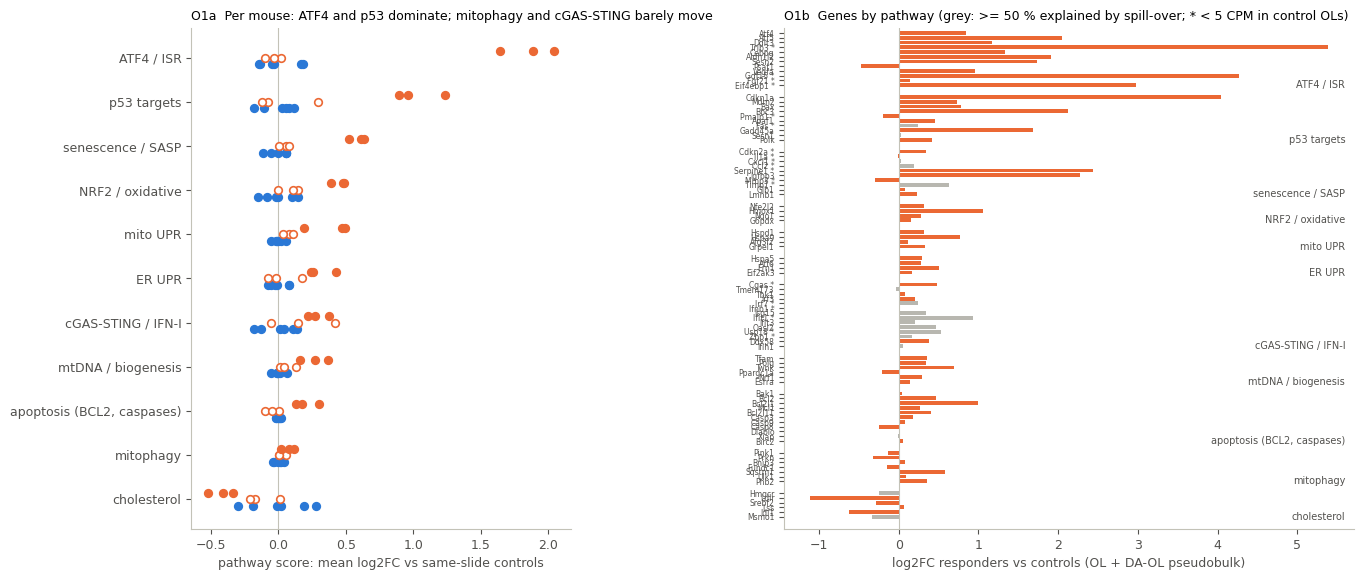

In [2]:
RT = REPO / "results" / "region_time"
meta = pd.read_csv(RT / "pseudobulk_meta.csv", index_col=0)
counts = pd.read_csv(RT / "pseudobulk_counts.csv", index_col=0)
m = meta[meta.region == "All regions"].assign(ct=lambda d: d.cell_type.replace({"DA-Oligodendrocytes": "Oligodendrocytes",
            "Excitatory Neurons": "Neurons", "GABAergic Neurons": "Neurons", "Medium Spiny Neurons": "Neurons"}))
X = counts.loc[m.index].groupby([m.ct, m.sample_id]).sum()
cpm = X.div(X.sum(1), axis=0) * 1e6
OL = cpm.loc["Oligodendrocytes"].loc[order]
Z = slide_centre(np.log2(OL + 1))
base_cpm = OL.loc[ctrl].mean()

# spill-over check (analysis/12): share of each OL change predicted from the other cell types' changes
def group_mean(g):
    return sum(cpm.loc[(slice(None), [s for s in grp.index if grp[s] == g and age[s] == a]), :].groupby(level=0).mean() for a in (21, 60)) / 2
C_ctrl, C_resp = group_mean("control"), group_mean("responder")
SOURCES = ["Oligodendrocytes", "Microglia", "Astrocytes", "Endothelial Cells", "Neurons"]
alpha = sp.contamination(C_ctrl, sp.source_markers(C_ctrl, SOURCES))
delta = C_resp - C_ctrl
spill = sp.spill_fraction(delta.loc[["Oligodendrocytes"]], sp.expected_spill(alpha, delta).loc[["Oligodendrocytes"]]).iloc[0]

rows, prow = [], []
for name, genes in MECHANISM_SETS.items():
    g = [x for x in genes if x in Z]
    sc = Z[g].mean(1)
    d, p = co.exact_perm(sc, resp, ctrl)
    prow.append({"pathway": name, "n_genes": len(g), "resp_log2fc": sc[resp].mean(), "ctrl_min": sc[ctrl].min(), "ctrl_max": sc[ctrl].max(),
                 "nonresp_log2fc": sc[nonr].mean(), "p_resp": p})
    for x in g:
        rows.append({"pathway": name, "gene": x, "ctrl_cpm": base_cpm[x], "resp_log2fc": Z.loc[resp, x].mean(), "nonresp_log2fc": Z.loc[nonr, x].mean(),
                     "spill_fraction": spill.get(x, np.nan)})
path = save_table(pd.DataFrame(prow).round(3), "pathway_scores", index=False)
genes_t = save_table(pd.DataFrame(rows).round(3), "pathway_genes", index=False)
display(path.sort_values("resp_log2fc", ascending=False))

po = path.sort_values("resp_log2fc").pathway.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.5], "wspace": 0.45})
ax = axes[0]
for i, pw in enumerate(po):
    g = [x for x in MECHANISM_SETS[pw] if x in Z]; sc = Z[g].mean(1)
    for s in order:
        ax.scatter(sc[s], i + {"control": -0.15, "non-responder": 0, "responder": 0.15}[grp[s]], s=30, linewidth=1.2, zorder=3, **STYLE[grp[s]])
ax.axvline(0, color=AXIS, lw=0.8); ax.set_yticks(range(len(po)), po); ax.set_xlabel("pathway score: mean log2FC vs same-slide controls")
ax.set_title("O1a  Per mouse: ATF4 and p53 dominate; mitophagy and cGAS-STING barely move", fontsize=9)
ax = axes[1]
y, ys, labels = 0, [], []
for pw in po[::-1]:
    for _, r in genes_t[genes_t.pathway == pw].iterrows():
        ax.barh(y, r.resp_log2fc, color=GREY if r.spill_fraction >= 0.5 else ORANGE, height=0.8)
        ys.append(y); labels.append(f"{r.gene}{' *' if r.ctrl_cpm < 5 else ''}"); y += 1
    ax.text(ax.get_xlim()[1] if False else 5.6, y - 1, pw, fontsize=7, ha="right", va="center", color=INK2)
    y += 1.5
ax.set_yticks(ys, labels, fontsize=5.5); ax.set_ylim(y, -1)
ax.axvline(0, color=AXIS, lw=0.8); ax.set_xlabel("log2FC responders vs controls (OL + DA-OL pseudobulk)")
ax.set_title("O1b  Genes by pathway (grey: >= 50 % explained by spill-over; * < 5 CPM in control OLs)", fontsize=9)
save(fig, "O1_pathway_map")
display(genes_t[genes_t.pathway.isin(["cGAS-STING / IFN-I", "senescence / SASP", "p53 targets"])].sort_values(["pathway", "resp_log2fc"], ascending=[True, False]))

**A.** These are pooled OL pseudobulks, so with roughly half of OLs responding (analysis/09) the change per
responding cell is larger; the ranking is what matters. Controls scatter within about +/-0.2 log2 for every
pathway, so a pathway-wide shift of ~0.3 would be visible.

* **ATF4 / ISR: +1.9**, the dominant programme (Trib3, Gdf15, Eif4ebp1, Atf5, Aldh1l2, Sesn2, Ddit3, Cebpg, Vegfa,
  Atf4 itself up; the serine-synthesis gene Psat1 slightly down).
* **p53 targets: +1.0**, mostly Cdkn1a (p21), Bbc3 (PUMA) and Gadd45a; Mdm2 and Bax modest; Pmaip1 (NOXA) and Fas
  flat. A DNA-damage / p53 arm alongside the ISR, as expected from double-strand breaks.
* **Pro-survival, not apoptosis**: Bcl2l1 (BCL-XL) +1.0 and Mcl1 up, executioner caspases flat. With PUMA up, the
  cells look primed but surviving, consistent with no OL loss beyond a modest drop in density (analysis/11).
* **Smaller adaptive arms**: NRF2 / oxidative (Hmox1 +1.1), mitochondrial UPR (Hspa9 +0.8, Hspd1 +0.3), ER UPR
  (+0.3), mtDNA maintenance (Twnk, Tfam, Polg +0.3-0.7).
* **Senescence: partial.** p21 is up, Serpine1 and Igfbp3 rise from low levels, but Cdkn2a (p16), Il1a, Cxcl1, Ccl2
  and Mmp3 stay flat: no classic SASP.
* **Mitophagy: no transcriptional response** (Pink1, Prkn, Bnip3, Fundc1 flat; only Sqstm1 +0.6).
* **cGAS-STING / type-I interferon: essentially absent.** Cgas, Tmem173 (STING), Tbk1, Irf3 and Ifnb1 are flat; the
  small rises in Ifit1, Oasl2 and Usp18 are on genes with < 20 CPM in OLs and match what spill-over from the
  astrocyte interferon response (analysis/12) predicts. So there is no evidence that cytosolic mtDNA triggers an
  innate response inside OLs; the response is a cell-intrinsic ISR + p53 programme.
* **Cholesterol uptake down** (Ldlr -1.1), alongside the myelin-gene loss.

Cgas itself is +0.5 log2, but from ~1 CPM (a handful of transcripts per mouse), with Tmem173, Tbk1, Irf3 and Ifnb1
flat; on its own it does not indicate pathway activity.

## B. Do OPCs respond?

,responders,non-responders,controls max
"OPCs (Pdgfra+, Mog-)",1.19,1.06,1.07
Astrocytes (spill-over level),1.21,1.04,1.08
Mature OLs (incl. DA-OL),4.21,1.01,1.12


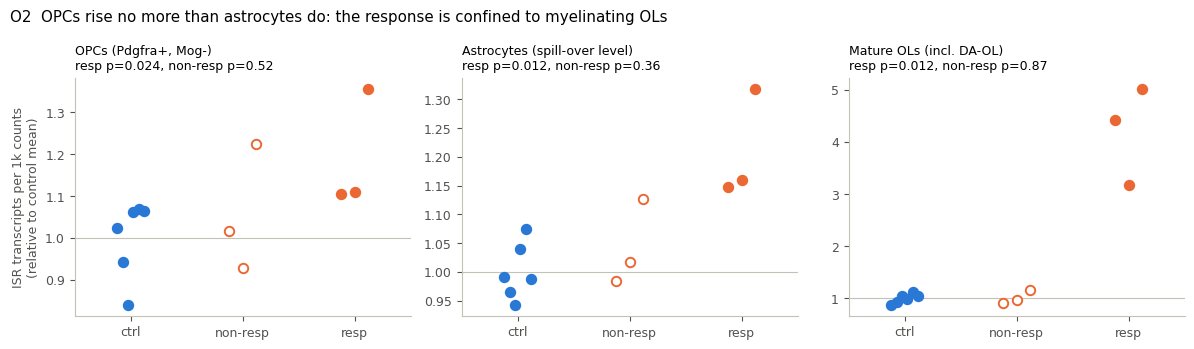

In [3]:
nc = pd.read_csv(REPO / "results" / "cell_table" / "nsc_ol_lineage_counts.csv.gz")
ISR = ["Trib3", "Atf5", "Ddit3", "Gdf15", "Sesn2", "Cebpg", "Cdkn1a"]
GROUPS = {"OPCs (Pdgfra+, Mog-)": (nc.cell_type == "Immature Oligodendrocytes I") & (nc.Pdgfra > 0) & (nc.Mog == 0),
          "Astrocytes (spill-over level)": nc.cell_type == "Astrocytes",
          "Mature OLs (incl. DA-OL)": nc.cell_type.isin(["Oligodendrocytes", "DA-Oligodendrocytes"])}
res = {}
for lab, mask in GROUPS.items():
    x = nc[mask]
    v = (x[ISR].sum(1) / x.total_counts * 1e3).groupby(x.sample_id).mean().loc[order]
    res[lab] = v / v[ctrl].mean()
opc = save_table(pd.DataFrame(res).round(4), "isr_by_lineage_stage")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=False)
for ax, lab in zip(axes, opc.columns):
    dots(ax, opc[lab], f"{lab}\n{ptxt(opc[lab])}", ylab="ISR transcripts per 1k counts\n(relative to control mean)" if ax is axes[0] else None, ref=1)
fig.suptitle("O2  OPCs rise no more than astrocytes do: the response is confined to myelinating OLs", x=0.01, ha="left")
fig.tight_layout(); save(fig, "O2_opc_isr")
display(pd.DataFrame({"responders": opc.loc[resp].mean(), "non-responders": opc.loc[nonr].mean(), "controls max": opc.loc[ctrl].max()}).round(2))

**B.** Per 1,000 counts, responder OLs (incl. DA-OLs) carry ~4.2x the control ISR transcripts. Pure OPCs (Pdgfra+,
no Mog) are at ~1.2x (controls up to 1.07x), the same as astrocytes (~1.2x), which have no reason to respond and pick up stressed-OL RNA through
segmentation spill-over. The OPC signal is therefore at the spill-over level: **OPCs do not mount the response**, as
expected if the Plp1-driven construct acts in myelinating cells. The precursor pool is intact and could in principle
replace damaged OLs; whether it does needs a later time point.

## C. Myelin RNA, counted without cell segmentation

gene,Trib3,Mag,Cldn11,Mog,Sox10,Cdkn1a,Opalin,Ermn,Olig2,Cnp,Snap25,Gfap,Mbp
share outside any cell,0.178,0.191,0.193,0.199,0.234,0.264,0.279,0.292,0.313,0.339,0.391,0.66,0.765


region,Cortex,Fiber tracts,Hypothalamus,Striatum,Thalamus
gene,,,,,
Cnp,0.19,0.25,0.17,0.15,0.32
Mbp,-0.03,0.01,-0.02,-0.04,-0.00
Mog,0.30,0.35,0.24,0.29,0.32
Opalin,0.25,0.32,0.07,0.23,0.29
Sox10,0.08,0.04,-0.07,0.13,-0.02


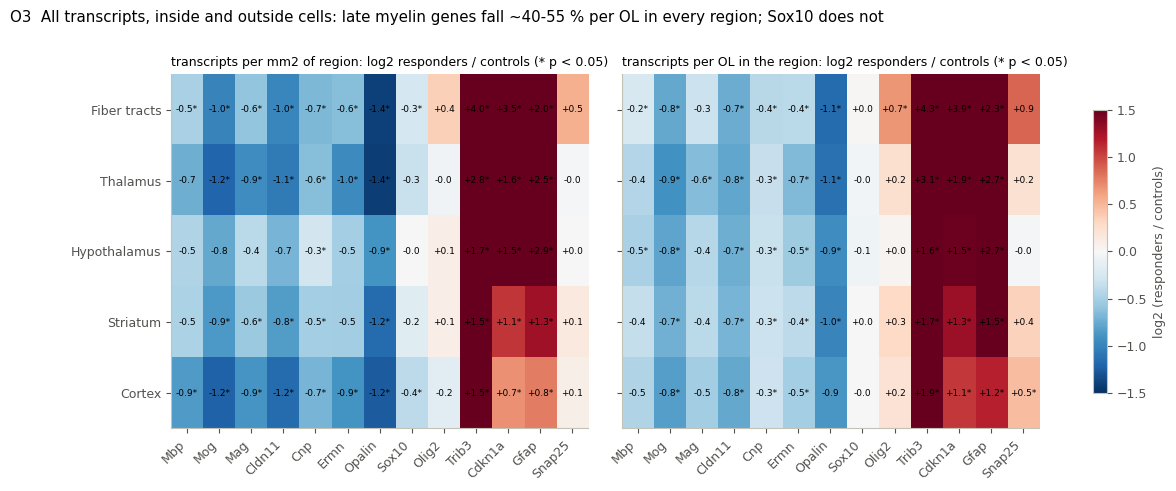

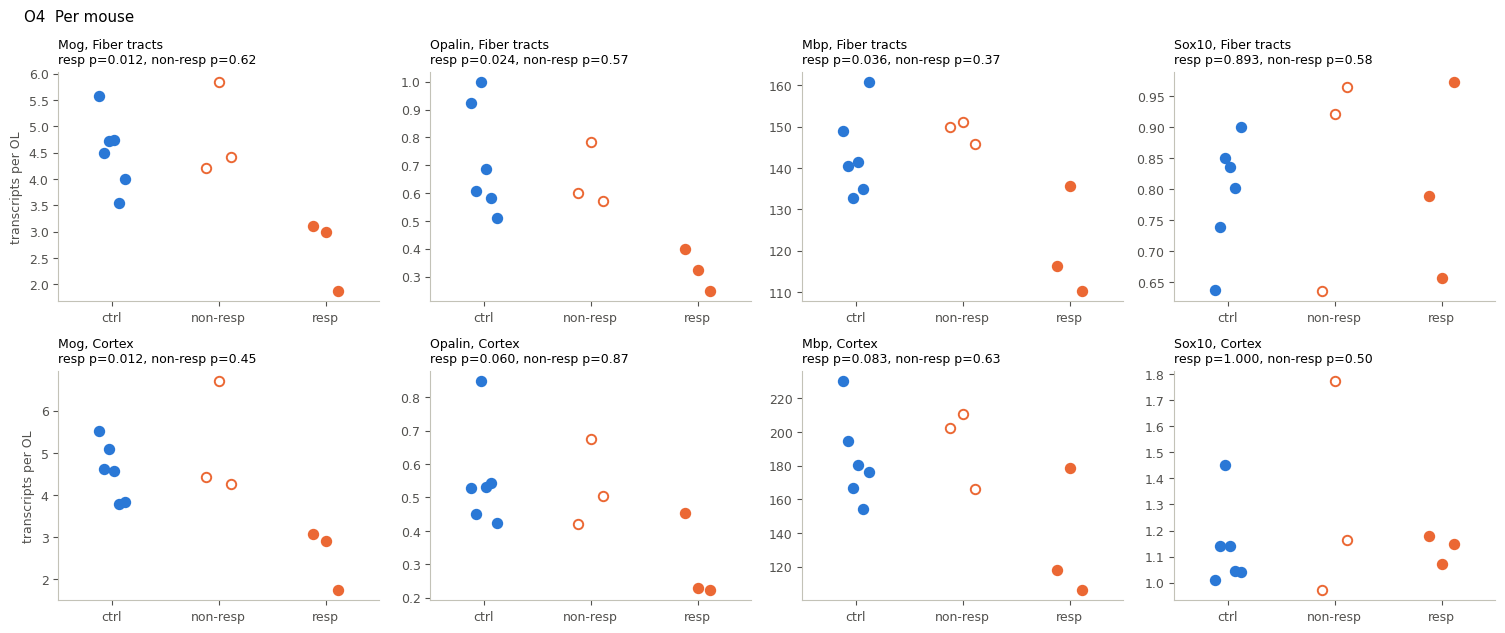

In [4]:
tx = pd.read_csv(REPO / "results" / "myelin_rna" / "myelin_tx_bins.csv.gz")
cells = pd.read_csv(REPO / "results" / "cell_table" / "cells.csv.gz", usecols=["sample_id", "cell_class", "RBD_compartment_simplified", "x_centroid", "y_centroid"]).rename(columns={"RBD_compartment_simplified": "region"})
BIN = 20
parts = []
for sid, t in tx.groupby("sample_id"):
    sec = cells[cells.sample_id == sid]
    b = t[["bx", "by"]].drop_duplicates()
    dist, idx = cKDTree(sec[["x_centroid", "y_centroid"]].to_numpy()).query(np.c_[(b.bx + 0.5) * BIN, (b.by + 0.5) * BIN])
    parts.append(t.merge(b.assign(region=sec.region.to_numpy()[idx], dist=dist), on=["bx", "by"]))
tx = pd.concat(parts)
tx = tx[tx.dist < 30]                          # drop bins off the tissue edge
tot = tx.groupby("gene")[["n", "n_unassigned"]].sum()
display((tot.n_unassigned / tot.n).rename("share outside any cell").round(3).sort_values().to_frame().T)
area = co.occupied_area(cells, ("sample_id", "region"), bin=50)
n_ol = cells[cells.cell_class.isin(["Oligodendrocytes", "DA-Oligodendrocytes"])].groupby(["sample_id", "region"]).size()
agg = tx.groupby(["sample_id", "region", "gene"])[["n", "n_unassigned"]].sum().reset_index()
agg = agg.join(area.rename("area_mm2"), on=["sample_id", "region"]).join(n_ol.rename("n_ol"), on=["sample_id", "region"])
agg["per_mm2"] = agg.n / agg.area_mm2; agg["per_ol"] = agg.n / agg.n_ol; agg["share_unassigned"] = agg.n_unassigned / agg.n
save_table(agg.round(4), "myelin_tx_by_region", index=False)

REG = ["Fiber tracts", "Thalamus", "Hypothalamus", "Striatum", "Cortex"]
GENES = ["Mbp", "Mog", "Mag", "Cldn11", "Cnp", "Ermn", "Opalin", "Sox10", "Olig2", "Trib3", "Cdkn1a", "Gfap", "Snap25"]
rows = []
for r in REG:
    for g in GENES:
        x = agg[(agg.region == r) & (agg.gene == g)].set_index("sample_id").reindex(order)
        for metric in ("per_mm2", "per_ol", "share_unassigned"):
            v = x[metric]
            _, p = co.exact_perm(v, resp, ctrl)
            rows.append({"region": r, "gene": g, "metric": metric, "ctrl_mean": v[ctrl].mean(), "resp_mean": v[resp].mean(), "p_resp": p,
                         "log2_resp_vs_ctrl": np.log2(v[resp].mean() / v[ctrl].mean())})
mt = save_table(pd.DataFrame(rows).round(4), "myelin_tx_tests", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"wspace": 0.08})
for ax, metric, lab in zip(axes, ("per_mm2", "per_ol"), ("transcripts per mm2 of region", "transcripts per OL in the region")):
    t = mt[mt.metric == metric].pivot(index="region", columns="gene", values="log2_resp_vs_ctrl").loc[REG, GENES]
    p = mt[mt.metric == metric].pivot(index="region", columns="gene", values="p_resp").loc[REG, GENES]
    im = ax.imshow(t, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.iat[i, j]:+.1f}" + ("*" if p.iat[i, j] < 0.05 else ""), ha="center", va="center", fontsize=6.5)
    ax.set_xticks(range(len(GENES)), GENES, rotation=45, ha="right"); ax.set_yticks(range(len(REG)), REG if ax is axes[0] else [])
    ax.set_title(f"{lab}: log2 responders / controls (* p < 0.05)", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.8, label="log2 (responders / controls)")
fig.suptitle("O3  All transcripts, inside and outside cells: late myelin genes fall ~40-55 % per OL in every region; Sox10 does not", x=0.01, ha="left", y=1.02)
save(fig, "O3_myelin_tx_heatmap")

fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
for j, g in enumerate(["Mog", "Opalin", "Mbp", "Sox10"]):
    for row, r in enumerate(["Fiber tracts", "Cortex"]):
        v = agg[(agg.region == r) & (agg.gene == g)].set_index("sample_id")["per_ol"].reindex(order)
        dots(axes[row, j], v, f"{g}, {r}\n{ptxt(v)}", ylab="transcripts per OL" if j == 0 else None)
fig.suptitle("O4  Per mouse", x=0.01, ha="left"); fig.tight_layout(); save(fig, "O4_myelin_tx_dots")
display(mt[(mt.metric == "share_unassigned") & mt.gene.isin(["Mbp", "Mog", "Opalin", "Cnp", "Sox10"])].pivot(index="gene", columns="region", values="log2_resp_vs_ctrl").round(2))

**C.** Counting every transcript in a region, whether or not it falls inside a cell:

* **Mog and Opalin**, late myelinating-OL genes, are down ~40-55 % per OL in every region (log2 -0.7 to -1.1, p < 0.05
  in nearly all), and more per mm2 of tissue (-0.9 to -1.4), since OL density also drops a little (analysis/11).
  Mag, Cldn11, Ermn and Cnp follow at smaller size. The cell-based estimate (finding 2) was not a segmentation artefact.
* **Mbp** (77 % of it outside cells) falls less: ~13-30 % per OL (log2 -0.2 to -0.5), with RB4401, the mildest
  responder, near controls. Mbp mRNA is long-lived in sheaths, so it may lag.
* Controls for the method: **Snap25** (neuronal) is flat everywhere, while **Gfap** (astrocytic) rises 2-3 log2 per
  mm2 in thalamus, hypothalamus and fibre tracts, i.e. strong astrocyte reactivity that the cell-based astrocyte
  scores understate, because two thirds of Gfap lies in processes outside cell outlines.
* **Sox10 and Olig2 per OL are unchanged**: the OLs keep their lineage identity and lose the myelin programme,
  rather than disappearing.
* The share of Mog / Opalin transcripts lying outside cells rises slightly in responders (e.g. Mog 0.20-0.30 vs
  0.16-0.20 in fibre tracts), compatible with smaller somata or mRNA redistributed to processes; not resolved here.

## Summary

* **Mechanism**: mtDNA breaks drive an **ATF4 / ISR + p53 (p21, PUMA)** programme with pro-survival BCL-XL, small
  NRF2 / mito-UPR arms, and **no cGAS-STING / interferon, no mitophagy and no classic SASP** inside OLs. For the bench:
  ISR (PERK / ISRIB) and p53 are the pathways to perturb; STING inhibition is unlikely to help OLs directly.
* **OPCs are spared**: their ISR signal is at the spill-over level, like astrocytes.
* **Myelin genes, not OLs, are lost**: Mog / Opalin down ~half per OL in every region by segmentation-free counts;
  Sox10 / Olig2 per OL unchanged; Mbp lags.